# 08: Explainability (global SHAP)

Which flow features does the XGBoost 13-class model rely on, overall and per attack class? SHAP values come from XGBoost's exact TreeSHAP on a class-stratified sample of the **group-split test set** (behaviors the model never saw in training). The `shap` package is used for plotting only.

In [1]:
import sys, json
from pathlib import Path
sys.path.append(str(Path("..").resolve()))

import numpy as np, pandas as pd, joblib, xgboost as xgb
import matplotlib.pyplot as plt, seaborn as sns, shap
from scipy.special import softmax

from src.explainability.shap_global import stratified_sample, shap_values, importance_table, class_profile

ROOT = Path("..").resolve()
FIGS, REPORTS = ROOT / "reports" / "figures", ROOT / "reports"
features = json.loads((REPORTS / "final_features.json").read_text())["features"]
classes = list(json.loads((REPORTS / "label_encoding.json").read_text()))
PER_CLASS = 300

C:\Machine_Learning-Capstone\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data = pd.read_parquet(ROOT / "data/processed/training_sample.parquet", columns=features + ["Label_Encoded", "split_group"])
test = data[data["split_group"].eq("test")].reset_index(drop=True)
rows = stratified_sample(test["Label_Encoded"].to_numpy(), PER_CLASS)
X, y = test.loc[rows, features], test.loc[rows, "Label_Encoded"].to_numpy()
model = joblib.load(ROOT / "saved_models" / "XGBoost_group.joblib")
print(f"{len(X):,} test flows, {len(classes)} classes, {len(features)} features")

3,900 test flows, 13 classes, 60 features


## Check: the SHAP values add up to the model's output
For every flow, the base value plus the 60 feature contributions must equal the raw margin of each class, and the softmax of those margins must equal the model's probabilities.

In [3]:
values, base = shap_values(model, X)                       # (rows, features, classes)
raw = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
margin = raw.sum(axis=2)                                   # contributions + bias, per class
print("probabilities from SHAP sums match predict_proba, max abs difference:",
      float(np.abs(softmax(margin, axis=1) - model.predict_proba(X)).max()))

probabilities from SHAP sums match predict_proba, max abs difference: 1.1324882507324219e-06


## Global importance
Mean absolute SHAP value per feature (averaged over the classes), in log-odds.

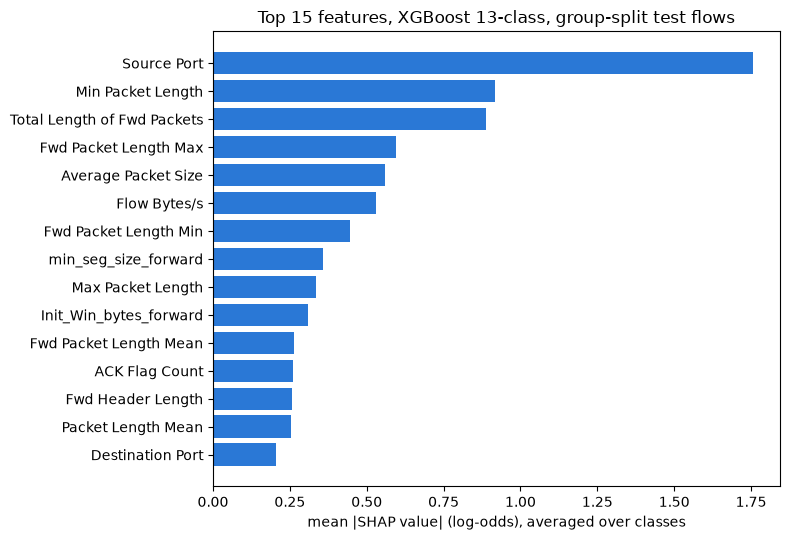

In [4]:
table = importance_table(values, features, classes)
table.round(4).to_csv(REPORTS / "shap_importance_xgboost_group.csv")
top = table["all classes"].head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color="#2a78d6")
ax.set_xlabel("mean |SHAP value| (log-odds), averaged over classes")
ax.set_title("Top 15 features, XGBoost 13-class, group-split test flows")
fig.tight_layout(); fig.savefig(FIGS / "shap_global_importance.png", dpi=150); plt.show()

## Which features matter for which attack
Mean absolute SHAP value of the 15 strongest features, per class.

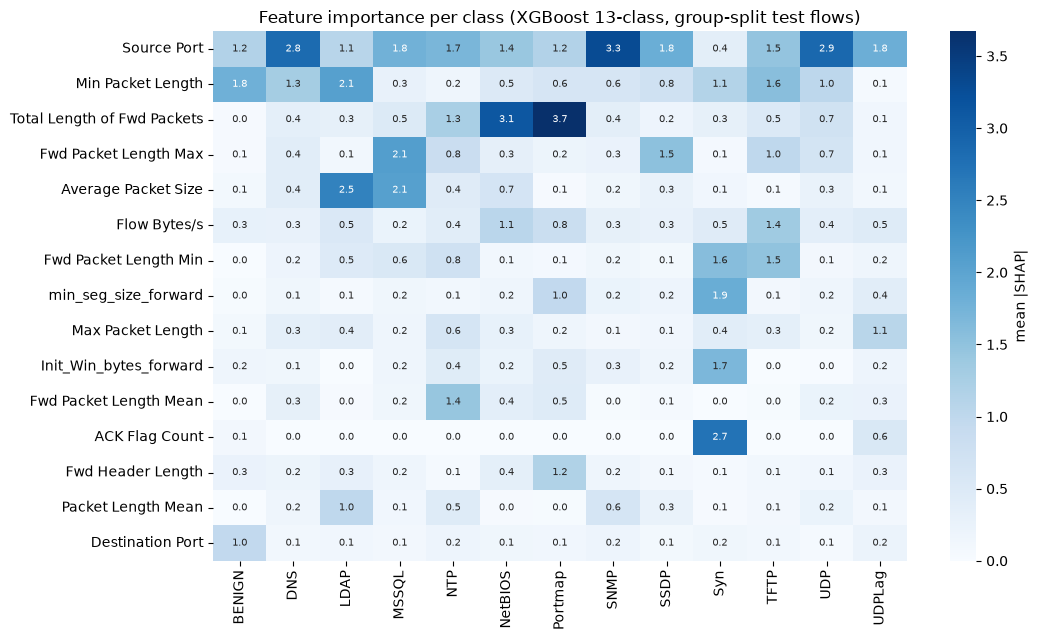

'  class                                                                                                        top features\n BENIGN                               Inbound (1.93), Min Packet Length (1.80), Source Port (1.16), Destination Port (0.97)\n    DNS              Source Port (2.83), Min Packet Length (1.30), Average Packet Size (0.41), Fwd Packet Length Max (0.41)\n   LDAP                 Average Packet Size (2.52), Min Packet Length (2.07), Source Port (1.09), Packet Length Mean (1.00)\n  MSSQL          Fwd Packet Length Max (2.11), Average Packet Size (2.07), Source Port (1.79), Fwd Packet Length Min (0.55)\n    NTP Source Port (1.70), Fwd Packet Length Mean (1.44), Total Length of Fwd Packets (1.25), Fwd Packet Length Max (0.85)\nNetBIOS             Total Length of Fwd Packets (3.12), Source Port (1.43), Flow Bytes/s (1.06), Average Packet Size (0.65)\nPortmap       Total Length of Fwd Packets (3.67), Fwd Header Length (1.16), Source Port (1.15), min_seg_size_forward (0.97)\

In [5]:
top_features = table.head(15).drop(columns="all classes")
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(top_features, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "mean |SHAP|"}, annot_kws={"size": 7}, ax=ax)
ax.set_title("Feature importance per class (XGBoost 13-class, group-split test flows)")
fig.tight_layout(); fig.savefig(FIGS / "shap_class_feature_heatmap.png", dpi=150); plt.show()
class_profile(table, top=4).to_string(index=False)

## How feature values move a class
Beeswarm plots for three classes with different behavior: one clean (NTP), one with an easily confused neighbor (DNS), and Syn.

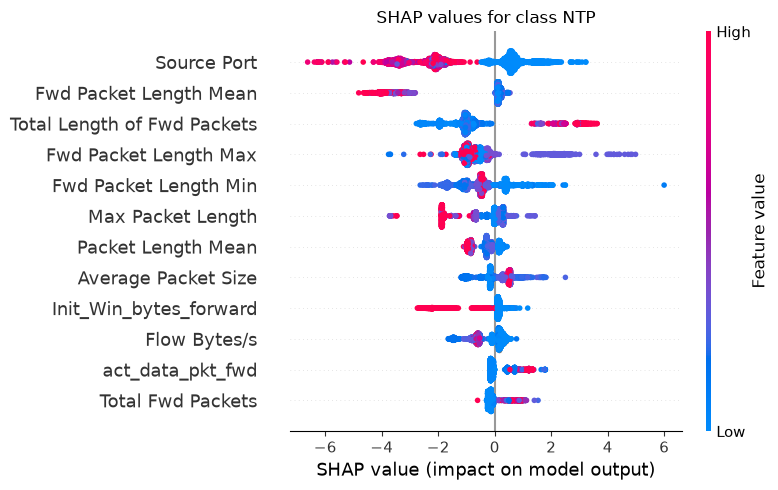

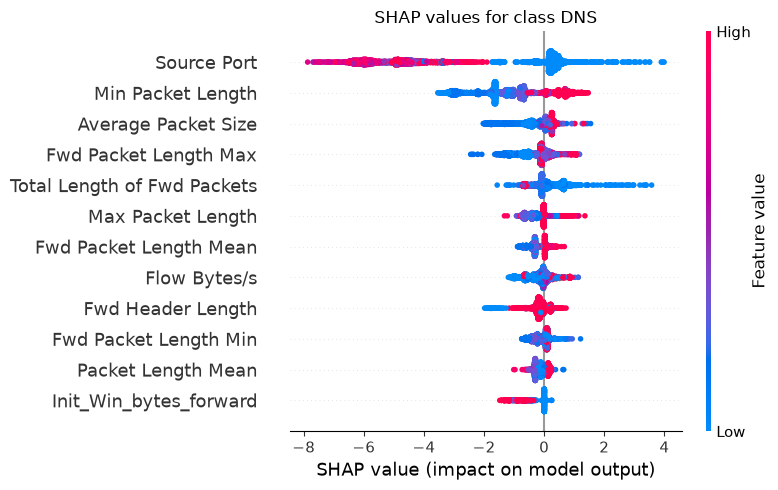

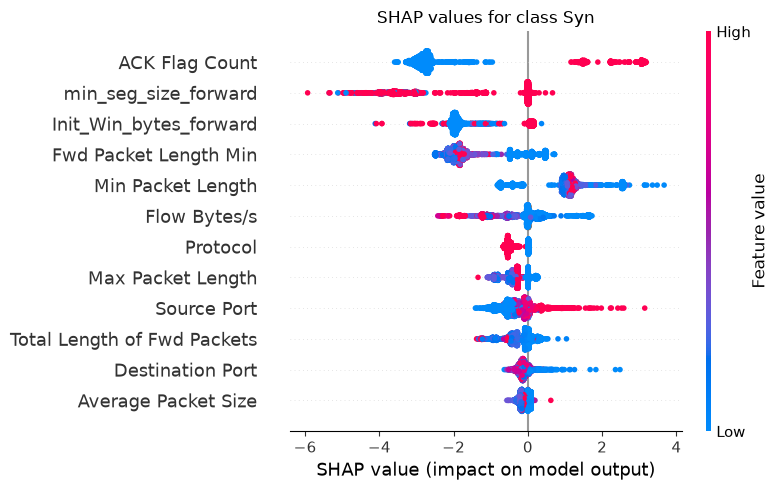

In [6]:
for name in ["NTP", "DNS", "Syn"]:
    c = classes.index(name)
    plt.figure(figsize=(8, 5))
    shap.summary_plot(values[:, :, c], X, max_display=12, show=False, plot_size=None)
    plt.title(f"SHAP values for class {name}")
    plt.tight_layout(); plt.savefig(FIGS / f"shap_beeswarm_{name}.png", dpi=150); plt.show()

## Reading the results
- **Source Port** is the single most influential feature overall and the top feature for DNS, SNMP and UDP. A high source port pushes a flow strongly away from DNS (reflected DNS replies come from port 53). This matches the earlier ablation: ports carry real signal beyond the behavior-only ceiling, but are partly junk on IP fragments.
- **Size features** (minimum packet length, total forward bytes, average packet size, maximum forward packet length) separate the classes that ports cannot: total forward bytes dominates NetBIOS and Portmap, average packet size dominates LDAP and MSSQL.
- **Syn** is the one class driven by TCP flags and window size (ACK flag count, forward window bytes, minimum segment size); every other attack is UDP-based and is told apart by ports and packet sizes.
- **BENIGN** is identified by direction and packet size (Inbound, minimum packet length), which is why it is solved at 0.99 to 1.00.